In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("C:/Users/moham/Downloads/messy_sales_prediction_dataset.csv")

In [3]:
print("Shape:", df.shape)

df.head()

Shape: (60900, 27)


,Order_ID,Order_Date,Customer_ID,Product_ID,Product_Name,Category,Region,City,Customer_Segment,Sales_Channel,...,Inventory_Level,Holiday,Promotion,Delivery_Days,Gross_Sales,Discount_Amount,Sales,Cost,Profit,Customer_Rating
0,ORD117503,2022-10-05,CUST06569,P006,Smart Watch,Accessories,Central,Bhopal,Consumer,Distributor,...,252.0,No,No,4,3110.11,0.00,3110.11,1897.63,1206.93,3.9
1,ORD146115,2025-10-28,CUST04340,P006,Smart Watch,Accessories,Central,Bhopal,Consumer,Distributor,...,346.0,No,No,4,3792.30,0.00,3792.30,3069.62,707.22,4.7
2,ORD159783,2025-06-30,CUST06734,P008,Standing Desk,Furniture,Central,Nagpur,Consumer,MARKETPLACE,...,348.0,No,No,3,5272.25,790.84,4481.41,2861.30,1599.12,3.6
3,ORD111461,2025-03-05,CUST04495,P016,Monitor 27,Electronics,West,Pune,Consumer,Retail Store,...,400.0,No,No,3,4412.95,0.00,4412.95,2892.98,1515.13,3.6
4,ORD150029,2022-06-24,CUST01799,P009,Coffee Maker,Home Appliances,South,Kochi,Corporate,Online,...,NaN,No,No,3,2223.37,0.00,2223.37,1440.03,779.51,3.3


In [5]:
# Task 1: Data Cleaning
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60900 entries, 0 to 60899
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           60900 non-null  object 
 1   Order_Date         60900 non-null  object 
 2   Customer_ID        60170 non-null  object 
 3   Product_ID         60900 non-null  object 
 4   Product_Name       60900 non-null  object 
 5   Category           60900 non-null  object 
 6   Region             60900 non-null  object 
 7   City               60413 non-null  object 
 8   Customer_Segment   60900 non-null  object 
 9   Sales_Channel      60900 non-null  object 
 10  Sales_Rep          59987 non-null  object 
 11  Payment_Method     60291 non-null  object 
 12  Quantity           60900 non-null  int64  
 13  Returned_Quantity  60900 non-null  int64  
 14  Unit_Price         60900 non-null  float64
 15  Discount_Pct       60414 non-null  float64
 16  Marketing_Spend    601

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,60900,60000,ORD128423,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,60900,1461,2024-06-16,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,60170,11925,CUST06878,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_ID,60900,20,P001,3126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,60900,20,Laptop Pro 14,3126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,60900,6,Electronics,18258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,60900,20,West,14175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,60413,20,Pune,3659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Segment,60900,3,Consumer,37813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales_Channel,60900,14,Online,25602,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
#Missing Value
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

missing = missing[missing['Missing_Count'] > 0].sort_values(
    'Missing_Count', ascending=False
)

missing

,Missing_Count,Missing_Percentage
Customer_Rating,1522,2.499179
Sales_Rep,913,1.499179
Customer_ID,730,1.198686
Marketing_Spend,730,1.198686
Payment_Method,609,1.000000
Inventory_Level,609,1.000000
City,487,0.799672
Discount_Pct,486,0.798030


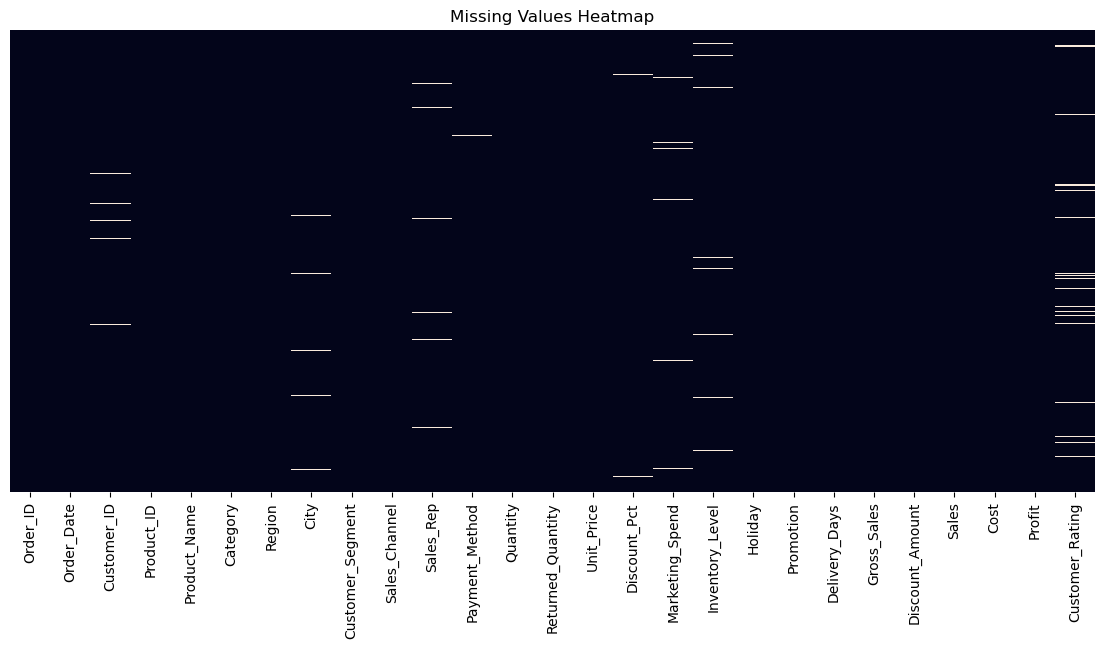

In [8]:
plt.figure(figsize=(14,6))

sns.heatmap(df.isnull(), 
            cbar=False, 
            yticklabels=False)

plt.title("Missing Values Heatmap")
plt.show()

In [9]:
categorical_missing = [
    'Customer_ID',
    'City',
    'Sales_Rep',
    'Payment_Method'
]

numeric_missing = [
    'Discount_Pct',
    'Marketing_Spend',
    'Inventory_Level',
    'Customer_Rating'
]

for col in categorical_missing:
    df[col] = df[col].fillna('Unknown')

for col in numeric_missing:
    df[col] = df[col].fillna(df[col].median())

In [10]:
### Missing Value Decisions
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 690


In [11]:
df = df.drop_duplicates()

In [12]:
print("Duplicate Order IDs:", df['Order_ID'].duplicated().sum())

Duplicate Order IDs: 210


In [13]:
df = df.drop_duplicates(subset='Order_ID', keep='first')

In [14]:
#Rename
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

In [15]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_id', 'product_name',
       'category', 'region', 'city', 'customer_segment', 'sales_channel',
       'sales_rep', 'payment_method', 'quantity', 'returned_quantity',
       'unit_price', 'discount_pct', 'marketing_spend', 'inventory_level',
       'holiday', 'promotion', 'delivery_days', 'gross_sales',
       'discount_amount', 'sales', 'cost', 'profit', 'customer_rating'],
      dtype='object')

In [16]:
#Fix Data type
df['order_date'] = pd.to_datetime(
    df['order_date'],
    errors='coerce',
    dayfirst=True
)

In [17]:
numeric_cols = [
    'quantity',
    'returned_quantity',
    'unit_price',
    'discount_pct',
    'marketing_spend',
    'inventory_level',
    'delivery_days',
    'gross_sales',
    'discount_amount',
    'sales',
    'cost',
    'profit',
    'customer_rating'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [18]:
outlier_cols = [
    'quantity',
    'unit_price',
    'discount_pct',
    'marketing_spend',
    'sales',
    'profit'
]

In [19]:
outlier_summary = []

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append([
        col, Q1, Q3, IQR, lower, upper, count
    ])

outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=[
        'Column','Q1','Q3','IQR',
        'Lower_Bound','Upper_Bound','Outlier_Count'
    ]
)

outlier_summary

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,quantity,18.0000,27.0000,9.0000,4.50000,40.50000,302
1,unit_price,70.0575,314.6550,244.5975,-296.83875,681.55125,6378
2,discount_pct,0.0000,10.0000,10.0000,-15.00000,25.00000,1014
3,marketing_spend,77.8600,241.2200,163.3600,-167.18000,486.26000,993
4,sales,1399.9950,5617.8425,4217.8475,-4926.77625,11944.61375,3167
5,profit,406.4500,1716.5875,1310.1375,-1558.75625,3681.79375,3422


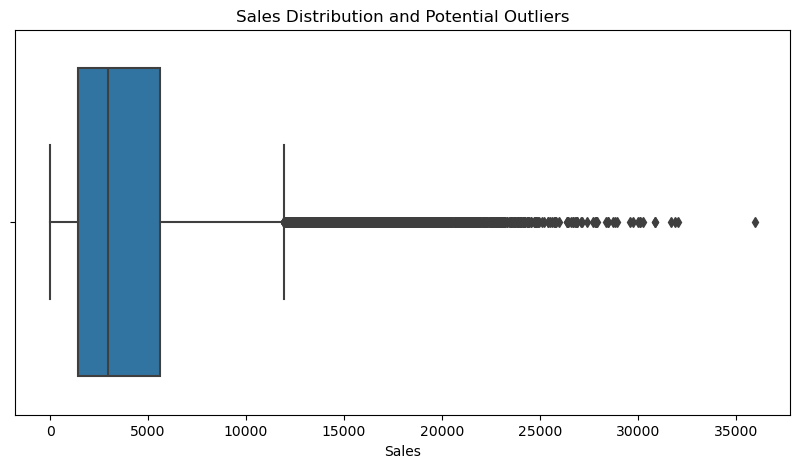

In [20]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['sales'])

plt.title("Sales Distribution and Potential Outliers")
plt.xlabel("Sales")

plt.show()

In [21]:
df.loc[df['unit_price'] < 0, 'unit_price'] = np.nan
df.loc[
    (df['discount_pct'] < 0) | (df['discount_pct'] > 100),
    'discount_pct'
] = np.nan

In [22]:
df['unit_price'] = df['unit_price'].fillna(df['unit_price'].median())
df['discount_pct'] = df['discount_pct'].fillna(df['discount_pct'].median())

In [23]:
encoding_cols = [
    'category',
    'region',
    'customer_segment',
    'sales_channel',
    'payment_method',
    'holiday',
    'promotion'
]

encoded_df = pd.get_dummies(
    df,
    columns=encoding_cols,
    dtype=int
)

encoded_df.head()

,order_id,order_date,customer_id,product_id,product_name,city,sales_rep,quantity,returned_quantity,unit_price,...,payment_method_Credit Card,payment_method_Debit Card,payment_method_Net Banking,payment_method_UPI,payment_method_Unknown,payment_method_Wallet,holiday_No,holiday_Yes,promotion_No,promotion_Yes
0,ORD117503,2022-05-10,CUST06569,P006,Smart Watch,Bhopal,SR014,22,0,141.37,...,0,1,0,0,0,0,1,0,1,0
1,ORD146115,NaT,CUST04340,P006,Smart Watch,Bhopal,SR015,26,0,145.86,...,1,0,0,0,0,0,1,0,1,0
2,ORD159783,NaT,CUST06734,P008,Standing Desk,Nagpur,SR004,18,0,292.90,...,0,0,0,0,0,0,1,0,1,0
3,ORD111461,2025-05-03,CUST04495,P016,Monitor 27,Pune,SR039,16,0,275.81,...,1,0,0,0,0,0,1,0,1,0
4,ORD150029,NaT,CUST01799,P009,Coffee Maker,Kochi,SR019,19,0,117.02,...,0,0,1,0,0,0,1,0,1,0


In [24]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

df.describe().T

Rows: 60000
Columns: 27

Missing values:
36430

Duplicate rows:
0


,count,mean,min,25%,50%,75%,max,std
order_date,23570,2023-12-30 12:57:25.736105216,2022-01-01 00:00:00,2023-01-06 00:00:00,2024-01-05 00:00:00,2025-01-02 00:00:00,2025-12-12 00:00:00,NaN
quantity,60000.0,22.750717,1.0,18.0,23.0,27.0,792.0,14.62317
returned_quantity,60000.0,0.287017,0.0,0.0,0.0,0.0,39.0,2.17901
unit_price,60000.0,251.801121,21.67,70.355,139.55,314.655,1201.09,277.496745
discount_pct,60000.0,7.150333,0.0,0.0,5.0,10.0,30.0,7.793827
marketing_spend,60000.0,174.479178,50.0,77.86,140.6,241.22,6871.2,134.415276
inventory_level,60000.0,229.764817,0.0,107.0,230.0,351.0,494.0,141.454425
delivery_days,60000.0,3.784633,1.0,3.0,4.0,5.0,10.0,1.746005
gross_sales,60000.0,4516.448589,0.0,1514.1325,3181.0,6029.955,41368.46,4319.562774
discount_amount,60000.0,367.041591,0.0,0.0,104.23,395.965,12410.54,733.392646


In [25]:
#Export Clean CSV
df.to_csv("clean_sales_data.csv", index=False)

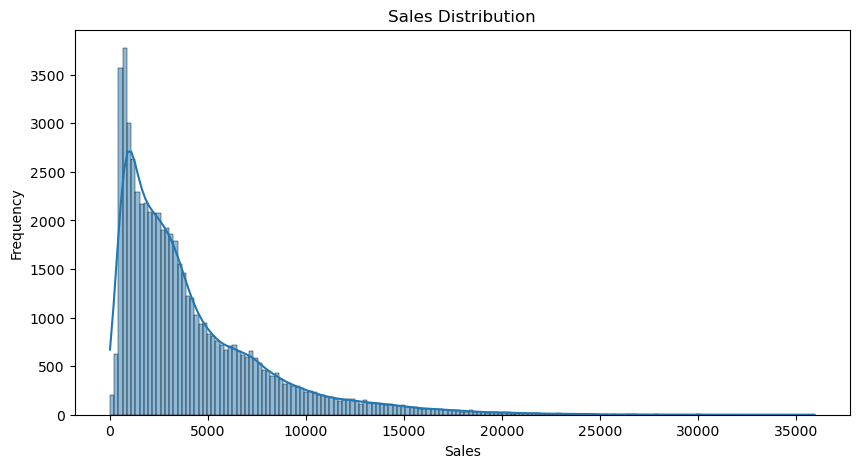

In [26]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['sales'],
    kde=True
)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

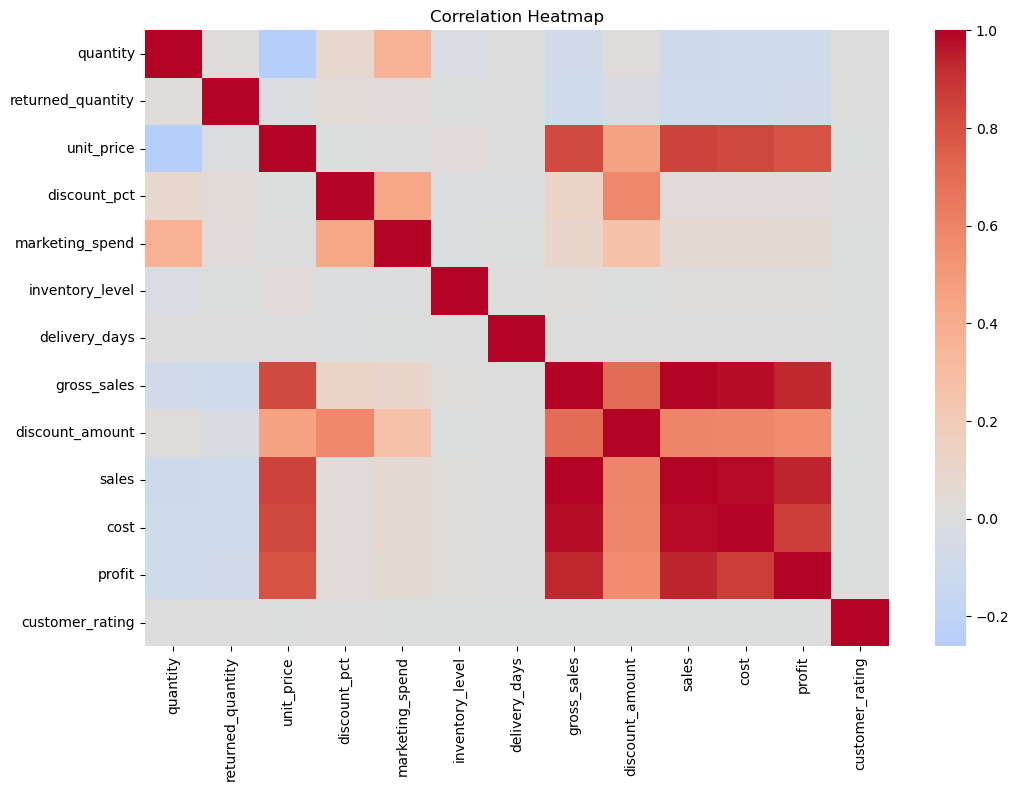

In [27]:
plt.figure(figsize=(12,8))

corr = df.select_dtypes('number').corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

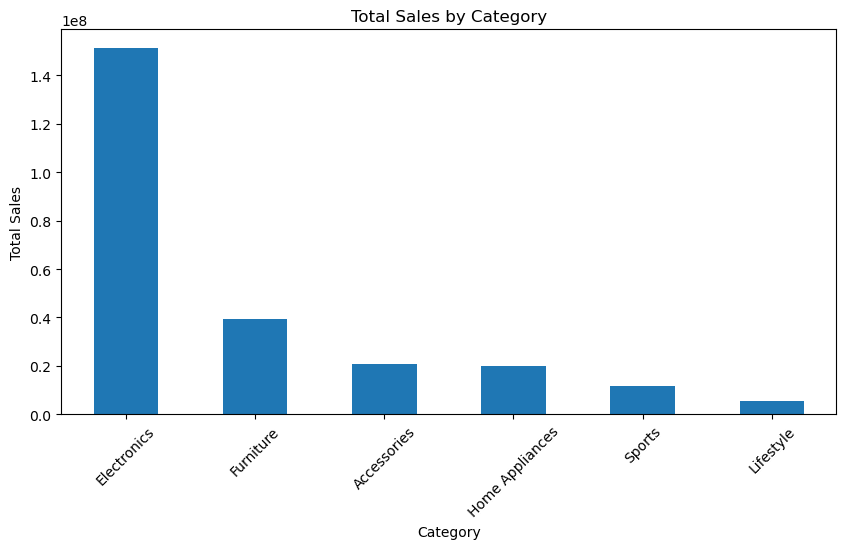

In [28]:
category_sales = (
    df.groupby('category')['sales']
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))

category_sales.plot(kind='bar')

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.show()

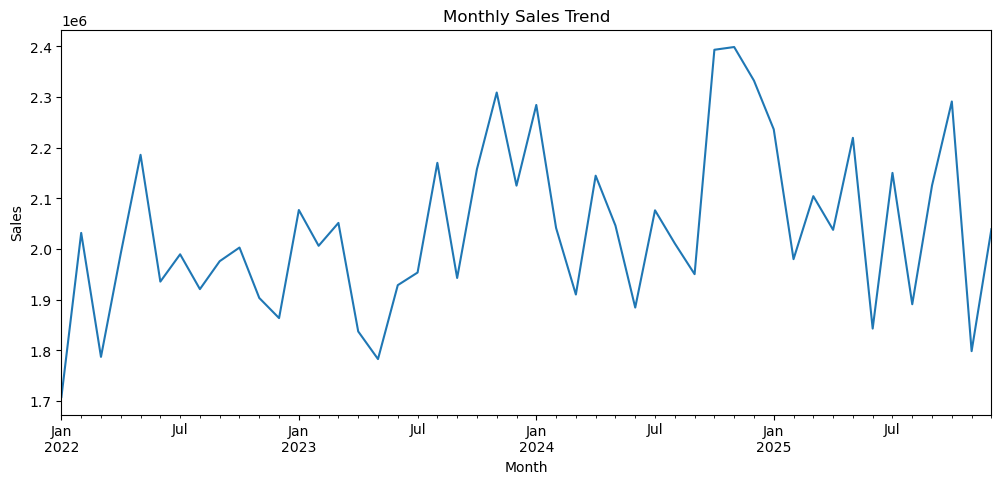

In [29]:
monthly_sales = (
    df.set_index('order_date')
      .resample('M')['sales']
      .sum()
)

plt.figure(figsize=(12,5))

monthly_sales.plot()

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.show()

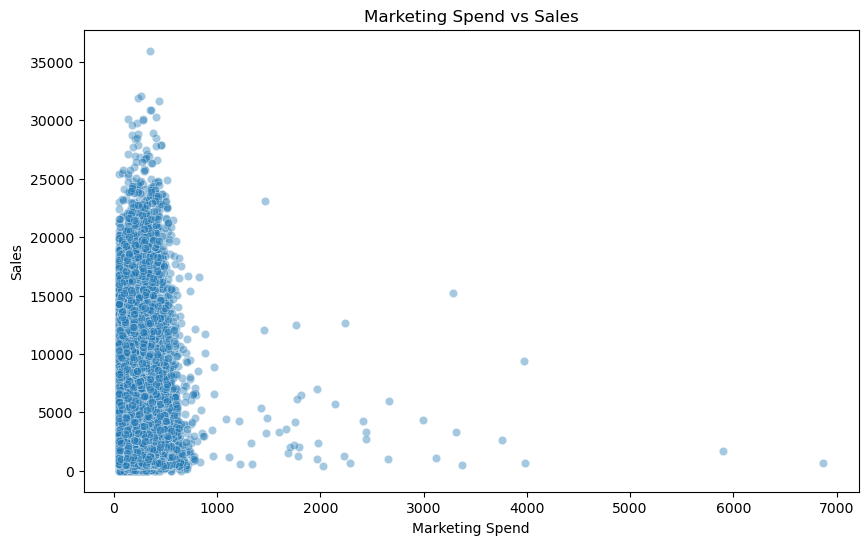

In [30]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='marketing_spend',
    y='sales',
    alpha=0.4
)

plt.title("Marketing Spend vs Sales")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales")

plt.show()

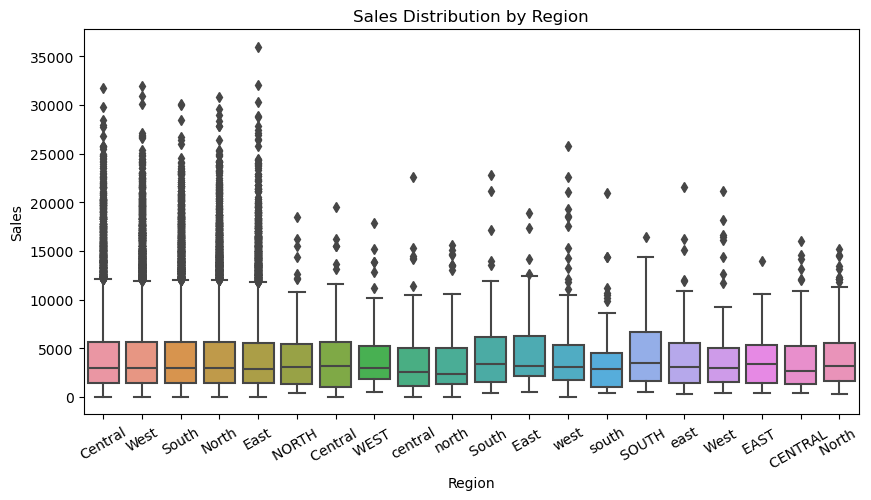

In [31]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='region',
    y='sales'
)

plt.title("Sales Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.xticks(rotation=30)

plt.show()

In [32]:
df.groupby('category').agg(
    total_sales=('sales','sum'),
    average_sales=('sales','mean'),
    total_profit=('profit','sum'),
    total_quantity=('quantity','sum')
).sort_values(
    'total_sales',
    ascending=False
)

,total_sales,average_sales,total_profit,total_quantity
category,,,,
Electronics,1.514123e+08,8421.617663,47441683.72,318440
Furniture,3.940775e+07,4400.150713,12349753.73,210081
Accessories,2.075556e+07,1736.285505,6392528.65,301929
Home Appliances,2.000786e+07,2217.674451,6176000.06,227589
Sports,1.185547e+07,1947.670836,3660583.24,153398
Lifestyle,5.525517e+06,920.612697,1674789.60,153606


In [33]:
df.groupby('region')['sales'].agg(
    ['sum','mean','median','count']
).sort_values(
    'sum',
    ascending=False
)

,sum,mean,median,count
region,,,,
West,58033036.71,4163.655956,2925.410,13938
North,53529621.98,4152.158081,2993.830,12892
South,48377705.08,4150.811247,2958.040,11655
Central,43895155.38,4170.561081,2971.070,10525
East,38893894.38,4097.113071,2895.250,9493
west,622830.80,4613.561481,3095.930,135
SOUTH,495713.25,4632.834112,3531.650,107
WEST,493291.32,4043.371475,2923.360,122
NORTH,474736.64,4128.144696,3062.930,115


In [34]:
#Task3
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['quarter'] = df['order_date'].dt.quarter
df['day_of_week'] = df['order_date'].dt.dayofweek

In [35]:
features = [
    'quantity',
    'unit_price',
    'discount_pct',
    'marketing_spend',
    'inventory_level',
    'delivery_days',
    'category',
    'region',
    'customer_segment',
    'sales_channel',
    'payment_method',
    'holiday',
    'promotion',
    'year',
    'month',
    'quarter',
    'day_of_week'
]

X = df[features]
y = df['sales']

In [36]:
df = df.sort_values('order_date')

split = int(len(df) * 0.8)

train = df.iloc[:split]
test = df.iloc[split:]

In [37]:
X_train = train[features]
y_train = train['sales']

X_test = test[features]
y_test = test['sales']

In [38]:
categorical_features = [
    'category',
    'region',
    'customer_segment',
    'sales_channel',
    'payment_method',
    'holiday',
    'promotion'
]

numeric_features = [
    'quantity',
    'unit_price',
    'discount_pct',
    'marketing_spend',
    'inventory_level',
    'delivery_days',
    'year',
    'month',
    'quarter',
    'day_of_week'
]

In [39]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ))
        ]), categorical_features)
    ]
)

In [40]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [41]:
lr_mae = mean_absolute_error(y_test, lr_pred)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_pred)
)

lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2:", lr_r2)

Linear Regression
MAE: 1103.2397486221905
RMSE: 1832.6777642174231
R2: 0.7658792529008629


In [42]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [43]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

Random Forest
MAE: 137.21393204999995
RMSE: 584.8195553591133
R2: 0.9761597144675317


In [44]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        lr_mae,
        rf_mae
    ],
    'RMSE': [
        lr_rmse,
        rf_rmse
    ],
    'R2': [
        lr_r2,
        rf_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,1103.239749,1832.677764,0.765879
1,Random Forest,137.213932,584.819555,0.976160


In [45]:
## Model Comparison

#The models were evaluated using MAE, RMSE and R².

#Lower MAE and RMSE indicate lower prediction error, while a higher R²
#indicates that the model explains more variance in the target variable.

#The model with the strongest overall test performance was selected as the
#preferred model.

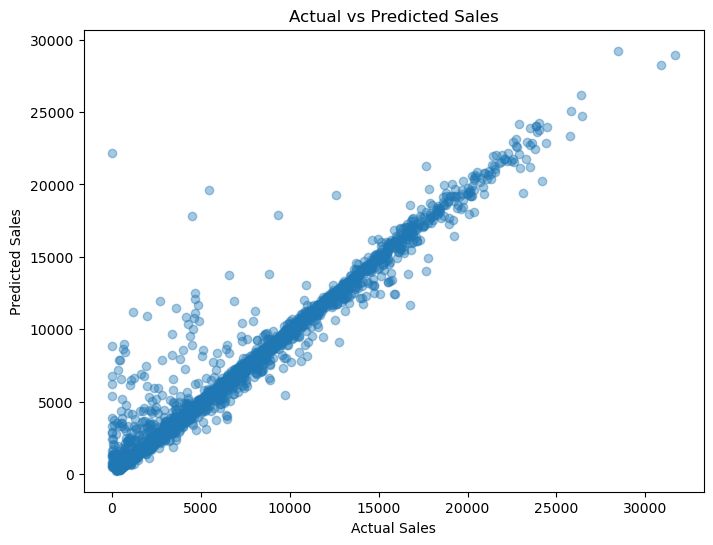

In [46]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.4
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

In [47]:
feature_names = (
    rf_model.named_steps['preprocessor']
    .get_feature_names_out()
)

importances = (
    rf_model.named_steps['model']
    .feature_importances_
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    'Importance',
    ascending=False
).head(15)

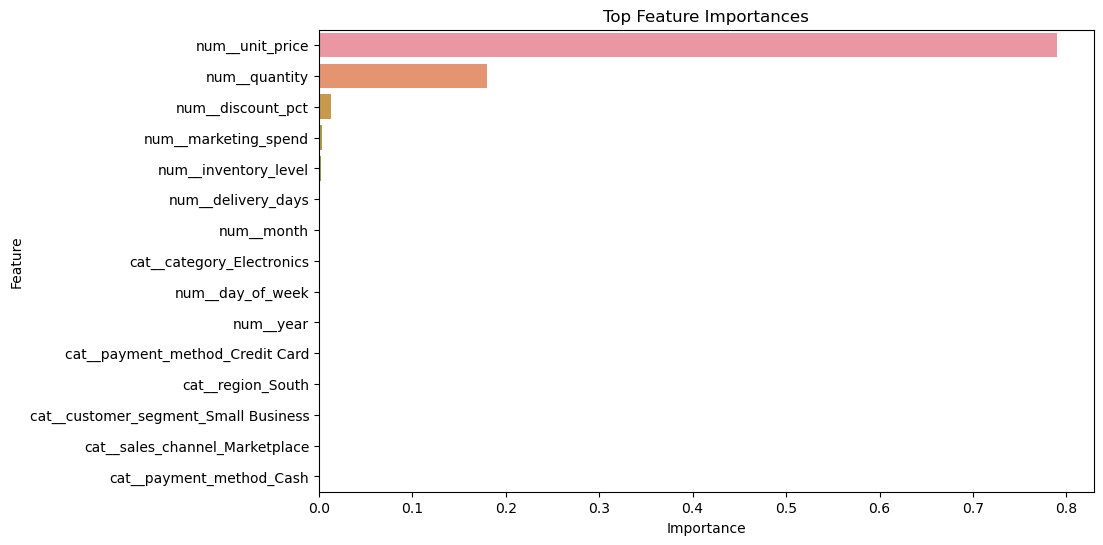

In [48]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Top Feature Importances")
plt.show()

In [49]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'model__n_estimators': [100, 150],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5]
}

In [50]:
search = RandomizedSearchCV(
    rf_model,
    param_distributions=param_grid,
    n_iter=3,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               SimpleImputer(strategy='median'),
                                                                               ['quantity',
                                                                                'unit_price',
                                                                                'discount_pct',
                                                                                'marketing_spend',
                                                                                'inventory_level',
                                                                                'delivery_days',
                                                                                'year',
                                                                                'month',
                                                                                'quarter',
                                                                                'day_of_week']),
                                                                              ('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('on...
                                                                               ['category',
                                                                                'region',
                                                                                'customer_segment',
                                                                                'sales_channel',
                                                                                'payment_method',
                                                                                'holiday',
                                                                                'promotion'])])),
                                             ('model',
                                              RandomForestRegressor(n_jobs=-1,
                                                                    random_state=42))]),
                   n_iter=3, n_jobs=-1,
                   param_distributions={'model__max_depth': [10, 20, None],
                                        'model__min_samples_split': [2, 5],
                                        'model__n_estimators': [100, 150]},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [51]:
print(search.best_params_)

{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__max_depth': None}


In [52]:
best_model = search.best_estimator_

best_pred = best_model.predict(X_test)

print("MAE:",
      mean_absolute_error(y_test, best_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, best_pred)))

print("R2:",
      r2_score(y_test, best_pred))

MAE: 136.5547892836674
RMSE: 583.315606405088
R2: 0.9762821743597345
